# Lesson 4 — Monte Carlo and temporal-difference prediction

*Chapter I. RL foundations and tabular methods · Section 4 of the lecture notes*

**Foundations:** Silver Lecture 4; Sutton–Barto §§5.1–5.2, 6.1–6.3.

> **Learning goal.** Distinguish a sample return from a bootstrap target; compute one MC/TD update and explain bias, variance.

> **How to read this notebook.** Markdown cells are the lecture, translated to English without changing its content. Boxes that start with **Code** map it to `prediction.py` (`MonteCarloPrediction`, `TD0Prediction`) and `experiment_random_walk.py` (the 5-state random walk of Sutton–Barto Example 6.2).

In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt

from rlcore import RandomWalk, TabularPolicy, rollout
from prediction import MonteCarloPrediction, TD0Prediction
import experiment_random_walk

env = RandomWalk(n=5, seed=0)               # L  A B C D E  R ; start in C; +1 on the right end
policy = TabularPolicy(env.uniform_policy())  # fixed policy: prediction, not control
rng = np.random.default_rng(0)
print("states:", env.state_names, "| true v_pi(A..E) =", env.true_values().round(3))

states: ['L', 'A', 'B', 'C', 'D', 'E', 'R'] | true v_pi(A..E) = [0.167 0.333 0.5   0.667 0.833]


## 1. Quick intuition

MC waits for the outcome of the episode and then uses the actual return as the target. TD uses the reward just received plus the estimated value of the next state. Both learn from data, without needing to know the transition model; TD still uses a learned prediction in its target, which is called bootstrapping. [Silver, Lecture 4]

## 2. The problem being solved

The policy $\pi$ is fixed; the input is trajectories/transitions from that policy, the output is $V \approx v_\pi$. This is prediction, not control yet. The objective of predicting value must be kept separate from RL's objective of choosing a policy. If the true value is known, measure the value error; if not, the Bellman residual/held-out targets only check the prediction aspect, they do not replace the task return.

> **Code.** The learners only receive trajectories from `rollout`; they never read `env.P` or `env.R`. The true values are used only to measure the error.

## 3. Core idea and formulas

$$V(S_t) \leftarrow V(S_t) + \alpha[G_t - V(S_t)]. \tag{12}$$

This is how to correct the estimate by **the discrepancy between the observed outcome and the old prediction**. $G_t$ is the return after the episode is complete; $G_t - V(S_t)$ is the prediction error. If the error is positive, increase $V$; if negative, decrease it. $\alpha$ decides how much to correct, it does not change the reward of the task. With $0 < \alpha \le 1$, the update moves from the old estimate toward the target. Choosing $\alpha = 1/N(S_t)$ according to the number of samples updated gives the sample mean.

First-visit MC updates the first time a state appears in an episode; every-visit uses every occurrence. Both need the episode and the way of counting samples to be defined. A return is a sample of a random variable, not the true value.

> **Code.** `MonteCarloPrediction(alpha=None)` uses $\alpha = 1/N(S_t)$, i.e. the sample mean; `first_visit` switches first-visit / every-visit. It refuses an episode that did not reach a terminal, since $G_t$ is not complete.

In [2]:
episode = rollout(env, policy, rng)
print("one episode:", [env.state_names[s] for s in episode.states], "rewards:", episode.rewards)

for first_visit in (True, False):
    mc = MonteCarloPrediction(env.n_states, alpha=None, first_visit=first_visit, terminal=env.terminal)
    run_rng = np.random.default_rng(1)
    for _ in range(2000):
        mc.learn_episode(rollout(env, policy, run_rng))
    print(f"{'first' if first_visit else 'every'}-visit MC, 2000 episodes: V =", mc.V[1:-1].round(3),
          "| samples per state N =", mc.N[1:-1])

one episode: ['C', 'D', 'C', 'B', 'A', 'B', 'C', 'D', 'E', 'R'] rewards: [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 1.0]


first-visit MC, 2000 episodes: V = [0.175 0.33  0.493 0.672 0.845] | samples per state N = [1230 1516 2000 1465 1166]


every-visit MC, 2000 episodes: V = [0.176 0.342 0.505 0.675 0.836] | samples per state N = [2031 4065 6042 4003 1995]


$$\delta_t = R_{t+1} + \gamma V(S_{t+1}) - V(S_t). \tag{13}$$

**Is the transition just seen better or worse than predicted?** TD builds the target $R_{t+1} + \gamma V(S_{t+1})$, then subtracts the current estimate $V(S_t)$. The difference is $\delta_t$. The target uses a real reward but uses *a prediction* for the future: this is bootstrapping. If $S_{t+1}$ is terminal, set $V(S_{t+1}) = 0$. A positive TD error does not mean a positive reward; it means the target is higher than the old prediction.

$$V(S_t) \leftarrow V(S_t) + \alpha\delta_t. \tag{14}$$

After computing the TD error, only correct the estimate of the state just visited by an amount $\alpha\delta_t$. For example, $\delta_t = 2$, $\alpha = 0.1$ increases $V(S_t)$ by $0.2$; if the error is $-2$ it decreases by $0.2$. The important point is that **it can learn right from one transition**, before the episode ends. The new number is still an estimate; one update does not make it the true value.

> **Code.** `TD0Prediction.update(s, r, s_next, terminal)` returns $\delta_t$ and changes only `V[s]`. The cell follows one episode transition by transition.

In [3]:
td = TD0Prediction(env.n_states, alpha=0.1, init_value=0.5, terminal=env.terminal)
for s, a, r, s_next, terminal in episode.transitions():
    before = td.V[s]
    delta = td.update(s, r, s_next, terminal)
    print(f"{env.state_names[s]} -> {env.state_names[s_next]}  R={r:.0f}  target={before + delta:.3f}  "
          f"delta={delta:+.3f}  V({env.state_names[s]}): {before:.3f} -> {td.V[s]:.3f}")

C -> D  R=0  target=0.500  delta=+0.000  V(C): 0.500 -> 0.500
D -> C  R=0  target=0.500  delta=+0.000  V(D): 0.500 -> 0.500
C -> B  R=0  target=0.500  delta=+0.000  V(C): 0.500 -> 0.500
B -> A  R=0  target=0.500  delta=+0.000  V(B): 0.500 -> 0.500
A -> B  R=0  target=0.500  delta=+0.000  V(A): 0.500 -> 0.500
B -> C  R=0  target=0.500  delta=+0.000  V(B): 0.500 -> 0.500
C -> D  R=0  target=0.500  delta=+0.000  V(C): 0.500 -> 0.500
D -> E  R=0  target=0.500  delta=+0.000  V(D): 0.500 -> 0.500
E -> R  R=1  target=1.000  delta=+0.500  V(E): 0.500 -> 0.550


**Reasoning.** Bellman expectation says the true value equals the expected one-step target. TD uses one realization of that target, then brings the current estimate closer to it. If the next-state estimate is wrong, the target may be wrong; if we wait for the whole episode, MC avoids bootstrapping but suffers the randomness of the whole path.

**Bias and variance.** The MC return is an unbiased target for the value of the policy that collects the data in the appropriate setting; the TD target suffers bias due to the current value approximation. MC usually has a large variance because of many random steps; TD usually reduces variance and learns earlier. This is a tendency, not a claim that TD is better than MC on every task. [Sutton–Barto, §6.2]

> **Code.** Measure both targets for state C under the fixed policy: the MC return from C vs the TD target $R + V(S')$ built with a deliberately wrong $V$ (all 0.5). The MC target is centred on $v_\pi(C) = 0.5$ with a large spread; the TD target has a small spread but its mean depends on $V$.

In [4]:
true_v = env.evaluate_policy_exact(env.uniform_policy())
C = env.state_index("C")
mc_targets, td_targets = [], []
V_wrong = np.where(env.terminal, 0.0, 0.5); V_wrong[env.state_index("D")] = 0.9   # a biased estimate of D
tr_rng = np.random.default_rng(2)
for _ in range(5000):
    traj = rollout(env, policy, tr_rng)
    mc_targets.append(traj.discounted_return(1.0))
    s1 = traj.states[1]
    td_targets.append(traj.rewards[0] + (0.0 if env.terminal[s1] else V_wrong[s1]))
for name, x in (("MC return", mc_targets), ("TD target", td_targets)):
    print(f"{name}: mean = {np.mean(x):.3f} (true v(C) = {true_v[C]:.3f}), variance = {np.var(x):.3f}")

MC return: mean = 0.502 (true v(C) = 0.500), variance = 0.250
TD target: mean = 0.700 (true v(C) = 0.500), variance = 0.040


## 4. Example and pipeline

Given $V(s) = 1, V(u) = 2$, transition $s \to u$ with reward $0$, $\gamma = 0.9$, $\alpha = 0.5$. The TD target is $1.8$, so the new $V(s)$ is $1.4$. If the episode afterwards receives reward $4$ and then ends, the MC return at $s$ is $3.6$, which gives the new $V(s)$ $2.3$ from the same initial estimate.

1. **Data:** MC collects complete episodes; TD can use each transition.
2. **Learning:** MC creates $G_t$; TD creates the reward plus the discounted next-state value; update $V$.
3. **Use and evaluation:** Prediction keeps the policy fixed; when it is plugged into control, policy changes must be taken into account.

In [5]:
td = TD0Prediction(2, gamma=0.9, alpha=0.5); td.V[:] = [1.0, 2.0]          # states s = 0, u = 1
print("TD target =", td.target(0.0, 1, False)); td.update(0, 0.0, 1, False); print("TD: new V(s) =", td.V[0])
mc = MonteCarloPrediction(2, gamma=0.9, alpha=0.5); mc.V[:] = [1.0, 2.0]
G = mc.target([0.0, 4.0], 0); mc.update(0, G)
print("MC return =", round(G, 3), "-> MC: new V(s) =", round(mc.V[0], 3))

TD target = 1.8
TD: new V(s) = 1.4
MC return = 3.6 -> MC: new V(s) = 2.3


## 5. Comparison, limits and applications

DP uses expectation and bootstraps; MC uses samples and does not bootstrap; TD uses samples and bootstraps. Tabular on-policy TD(0) has convergence guarantees with appropriate visitation and step sizes. When the policy changes, the target value changes with it; with function approximation/off-policy, the conditions are different. An example of prediction is estimating the total future cost of a controller in operation.

> **Code.** The experiment of Sutton–Barto Example 6.2: left, TD(0) estimates after 0, 1, 10, 100 episodes; right, RMS error averaged over states and runs for several $\alpha$. On this task TD learns faster for these step sizes, which is the tendency described above, not a general law. The figure and a JSON summary go to `artifacts/01_foundations_tabular/lesson_04_mc_td_prediction/`.

TD alpha=0.05    RMS after 10 episodes = 0.174, after 100 = 0.036
TD alpha=0.1     RMS after 10 episodes = 0.128, after 100 = 0.058
TD alpha=0.15    RMS after 10 episodes = 0.094, after 100 = 0.073
MC alpha=0.01    RMS after 10 episodes = 0.221, after 100 = 0.125
MC alpha=0.02    RMS after 10 episodes = 0.208, after 100 = 0.073
MC alpha=0.03    RMS after 10 episodes = 0.196, after 100 = 0.055
MC alpha=0.04    RMS after 10 episodes = 0.186, after 100 = 0.055


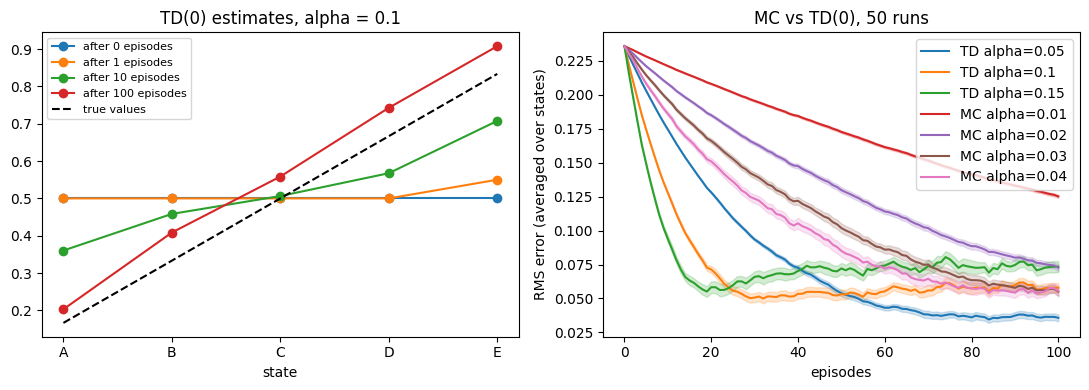

In [6]:
out = experiment_random_walk.run(runs=50, episodes=100)
for name, row in out["summary"].items():
    if isinstance(row, dict):
        print(f"{name:16s} RMS after 10 episodes = {row['rms_after_10']:.3f}, after 100 = {row['rms_final']:.3f}")
plt.show()

## 6. Exercises

1. With $V(s) = 2, V(u) = 5, R_{t+1} = 1, \gamma = 0.8, \alpha = 0.1$, compute the TD target, $\delta_t$ and the new estimate.
2. If the next state is terminal, what is the target?
3. Why can the MC target and the TD target differ on the same transition?

In [7]:
td = TD0Prediction(2, gamma=0.8, alpha=0.1); td.V[:] = [2.0, 5.0]
print("Exercise 1: target =", td.target(1.0, 1, False), "| delta =", td.td_error(0, 1.0, 1, False), end=" | ")
td.update(0, 1.0, 1, False); print("new V(s) =", round(td.V[0], 3))
print("Exercise 2: target when S_{t+1} is terminal =", td.target(1.0, 1, True))

Exercise 1: target = 5.0 | delta = 3.0 | new V(s) = 2.3
Exercise 2: target when S_{t+1} is terminal = 1.0


<details>
<summary><b>Answers (Appendix A)</b></summary>

(1) Target $1 + 0.8\cdot 5 = 5$; $\delta = 5 - 2 = 3$; new $V(s)$ $2.3$. (2) The target is only $R_{t+1}$ because the terminal value is zero. (3) MC uses the realized rewards of the remainder; TD uses the learned next-state estimate, so they do not necessarily coincide.
</details>

## 7. Remember and read further

Not bootstrapping does not mean having no stochastic error. The TD error is not a return. Read Silver 4 and Sutton–Barto §6.2; control is in Section 5.